In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, f1_score, v_measure_score

RUTA_DATOS = Path("datos")

In [4]:
def verificar_datos(conjunto):
    ruta = RUTA_DATOS / conjunto

    imagenes = sorted((ruta / "imagenes").glob("*.jpg"))
    mascaras = sorted((ruta / "mascaras").glob("*.png"))

    ids_imagenes = {p.stem for p in imagenes}
    ids_mascaras = {
        p.stem.replace("_Segmentation", "")
        for p in mascaras
    }

    print(f"{conjunto.upper()}")
    print(f"Imágenes: {len(imagenes)}")
    print(f"Máscaras: {len(mascaras)}")
    print(f"Parejas completas: {len(ids_imagenes & ids_mascaras)}")
    print(f"Imágenes sin máscara: {ids_imagenes - ids_mascaras}")
    print(f"Máscaras sin imagen: {ids_mascaras - ids_imagenes}")

verificar_datos("ajuste")
verificar_datos("prueba")

AJUSTE
Imágenes: 15
Máscaras: 15
Parejas completas: 15
Imágenes sin máscara: set()
Máscaras sin imagen: set()
PRUEBA
Imágenes: 5
Máscaras: 5
Parejas completas: 5
Imágenes sin máscara: set()
Máscaras sin imagen: set()


Aqui revisamos que no hayan imagenes sin su mascara.

In [5]:

def cargar_imagen(id_imagen, conjunto="ajuste", tamaño=(128, 128)):
    ruta = RUTA_DATOS / conjunto

    ruta_imagen = ruta / "imagenes" / f"{id_imagen}.jpg"
    ruta_mascara = ruta / "mascaras" / f"{id_imagen}_Segmentation.png"

    # Cargar imagen y convertir a RGB
    imagen = Image.open(ruta_imagen).convert("RGB")
    imagen = imagen.resize(tamaño, Image.Resampling.BILINEAR)

    # Cargar máscara y conservar sus valores binarios
    mascara = Image.open(ruta_mascara).convert("L")
    mascara = mascara.resize(tamaño, Image.Resampling.NEAREST)

    imagen = np.array(imagen)
    mascara = (np.array(mascara) > 127).astype(np.uint8)

    return imagen, mascara


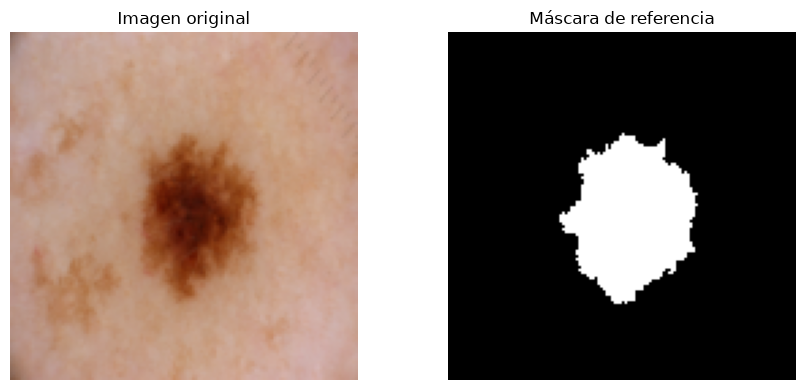

Dimensiones imagen: (128, 128, 3)
Dimensiones máscara: (128, 128)
Valores de máscara: [0 1]


In [6]:

imagen, mascara = cargar_imagen("ISIC_0000085")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara de referencia")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Dimensiones imagen:", imagen.shape)
print("Dimensiones máscara:", mascara.shape)
print("Valores de máscara:", np.unique(mascara))


In [7]:

class RepresentacionPixeles(BaseEstimator, TransformerMixin):

    def __init__(self, beta=1.0, lambda_=0.5):
        self.beta = beta
        self.lambda_ = lambda_

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        alto, ancho, _ = X.shape

        # Normalizar colores entre 0 y 1
        colores = X.reshape(-1, 3).astype(float) / 255.0

        # Coordenadas normalizadas entre 0 y 1
        y, x = np.indices((alto, ancho))

        x = x.ravel() / max(ancho - 1, 1)
        y = y.ravel() / max(alto - 1, 1)

        posiciones = np.column_stack((x, y))

        # Aplicar los pesos beta y lambda
        caracteristicas = np.column_stack((
            self.beta * colores,
            self.lambda_ * posiciones
        ))

        return caracteristicas


pipeline = Pipeline([
    ("representacion", RepresentacionPixeles(beta=1.0, lambda_=0.5))
])

X = pipeline.fit_transform(imagen)

print("Dimensiones de X:", X.shape)
print("Primer píxel:", X[0])


Dimensiones de X: (16384, 5)
Primer píxel: [0.53333333 0.40784314 0.37254902 0.         0.        ]


## Punto 2

Implementamos la selccion de K. Entrenando k-means con diferents opciones, calculando siluetas utilizando una muestra de hasta mil pixeles y devolviendo aquel que tenga la silueta mas alta


In [8]:

def seleccionar_k(X, muestra=1000, semilla=42):
    resultados = []

    for k in range(2, 9):
        modelo = KMeans(
            n_clusters=k,
            random_state=semilla,
            n_init=5
        )

        etiquetas = modelo.fit_predict(X)

        silueta = silhouette_score(
            X,
            etiquetas,
            sample_size=min(muestra, len(X)),
            random_state=semilla
        )

        resultados.append({
            "K": k,
            "Silueta": silueta
        })

    tabla = pd.DataFrame(resultados)
    mejor_k = int(tabla.loc[tabla["Silueta"].idxmax(), "K"])

    return mejor_k, tabla


In [9]:

# Recuperar la representación con color y posición
pipeline.set_params(
    representacion__beta=1.0,
    representacion__lambda_=0.5
)

X = pipeline.fit_transform(imagen)

mejor_k, tabla_k = seleccionar_k(X)

print(tabla_k)
print("\nMejor K:", mejor_k)


   K   Silueta
0  2  0.522892
1  3  0.385248
2  4  0.367476
3  5  0.417520
4  6  0.415755
5  7  0.377518
6  8  0.345284

Mejor K: 2


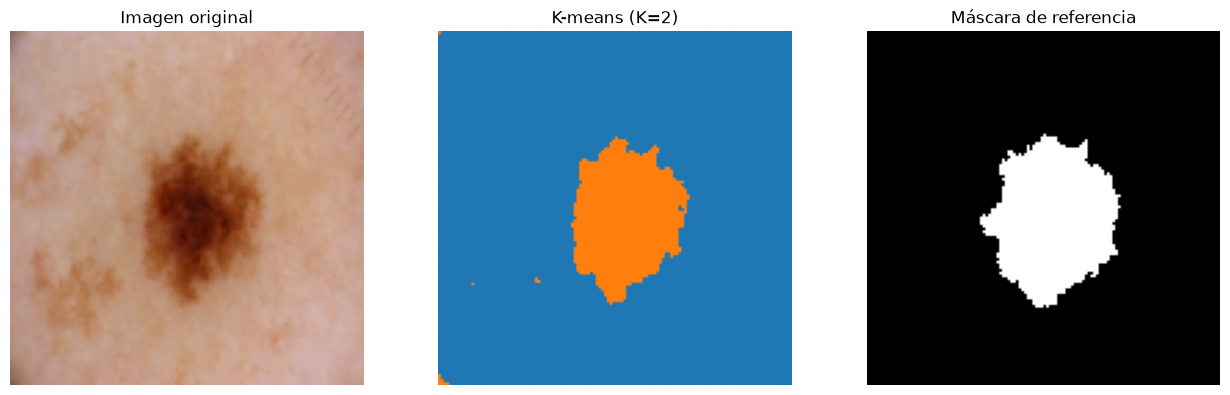

In [10]:

modelo = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=5
)

etiquetas = modelo.fit_predict(X)
grupos = etiquetas.reshape(imagen.shape[:2])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(grupos, cmap="tab10", vmin=0, vmax=9)
axes[1].set_title(f"K-means (K={mejor_k})")

axes[2].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Máscara de referencia")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Punto 3
Construccion de la mascara de lesión. Con los pixeles agrupados, ahora vamos a diseñar un criterio de identificación para las lesiones.
Un criterio inicial va ser considerar lesión el grupo con menor luminosidad promedio. Ya que las lesiones suelen ser más oscuras que la piel de alrededor. 

In [11]:

def crear_mascara(imagen, grupos):
    # Convertir imagen a valores entre 0 y 1
    imagen_normalizada = imagen.astype(float) / 255.0

    # Calcular luminosidad de cada píxel
    luminosidad = (
        0.2126 * imagen_normalizada[:, :, 0] +
        0.7152 * imagen_normalizada[:, :, 1] +
        0.0722 * imagen_normalizada[:, :, 2]
    )

    # Calcular luminosidad promedio por grupo
    promedios = {}

    for grupo in np.unique(grupos):
        promedios[grupo] = luminosidad[grupos == grupo].mean()

    # Elegir el grupo más oscuro
    grupo_lesion = min(promedios, key=promedios.get)

    # Crear máscara binaria
    mascara_predicha = (grupos == grupo_lesion).astype(np.uint8)

    return mascara_predicha, grupo_lesion


Ahora, calculamos dice. COn esto, miramos la coincidencia de  la predicción.

Grupo identificado como lesión: 1
Dice: 0.9025


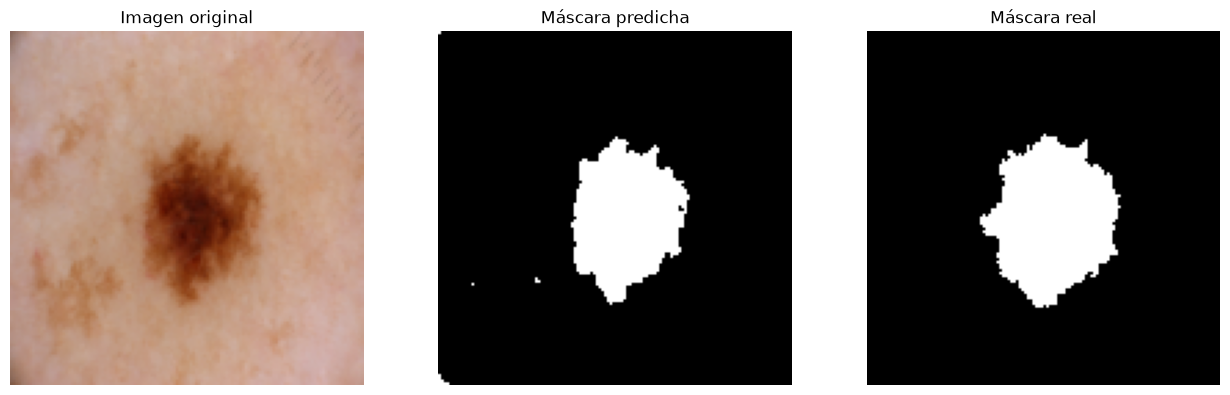

In [12]:

# Construir máscara a partir de K-means
mascara_predicha, grupo_lesion = crear_mascara(imagen, grupos)

# Calcular Dice
dice = f1_score(mascara.ravel(), mascara_predicha.ravel())

print("Grupo identificado como lesión:", grupo_lesion)
print(f"Dice: {dice:.4f}")

# Visualizar comparación
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(imagen)
axes[0].set_title("Imagen original")

axes[1].imshow(mascara_predicha, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara predicha")

axes[2].imshow(mascara, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Máscara real")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Punto 4

Ahora vamos a evaluar las combinaciones de beta y lambda sobre las 15 imagenes de ajuste. Con esto, podremos calcular el v-measure y los compararemos. 

In [13]:

def evaluar_configuracion(id_imagen, beta, lambda_):
    # 1. Cargar imagen y máscara
    imagen, mascara_real = cargar_imagen(id_imagen, "ajuste")

    # 2. Preparar características
    pipeline.set_params(
        representacion__beta=beta,
        representacion__lambda_=lambda_
    )
    X = pipeline.fit_transform(imagen)

    # 3. Seleccionar K mediante silueta
    mejor_k, tabla_k = seleccionar_k(X)

    # 4. Aplicar K-means
    modelo = KMeans(
        n_clusters=mejor_k,
        random_state=42,
        n_init=5
    )
    etiquetas = modelo.fit_predict(X)
    grupos = etiquetas.reshape(imagen.shape[:2])

    # 5. Construir máscara automáticamente
    mascara_predicha, grupo_lesion = crear_mascara(
        imagen, grupos
    )

    # 6. Calcular métricas
    dice = f1_score(
        mascara_real.ravel(),
        mascara_predicha.ravel(),
        zero_division=0
    )

    v_measure = v_measure_score(
        mascara_real.ravel(),
        etiquetas
    )

    mejor_silueta = tabla_k["Silueta"].max()

    return {
        "Imagen": id_imagen,
        "Beta": beta,
        "Lambda": lambda_,
        "K": mejor_k,
        "Silueta": mejor_silueta,
        "Dice": dice,
        "V-measure": v_measure
    }


In [14]:

resultado = evaluar_configuracion(
    "ISIC_0000085",
    beta=1.0,
    lambda_=0.5
)

pd.DataFrame([resultado])


,Imagen,Beta,Lambda,K,Silueta,Dice,V-measure
0,ISIC_0000085,1.0,0.5,2,0.522892,0.902548,0.760299


In [15]:

from itertools import product

# Valores que vamos a evaluar
betas = [0.5, 1.0]
lambdas = [0.0, 0.25, 0.5, 1.0, 2.0]

configuraciones = list(product(betas, lambdas))

print("Número de configuraciones:", len(configuraciones))

for beta, lambda_ in configuraciones:
    print(f"Beta: {beta}, Lambda: {lambda_}")


Número de configuraciones: 10
Beta: 0.5, Lambda: 0.0
Beta: 0.5, Lambda: 0.25
Beta: 0.5, Lambda: 0.5
Beta: 0.5, Lambda: 1.0
Beta: 0.5, Lambda: 2.0
Beta: 1.0, Lambda: 0.0
Beta: 1.0, Lambda: 0.25
Beta: 1.0, Lambda: 0.5
Beta: 1.0, Lambda: 1.0
Beta: 1.0, Lambda: 2.0


In [16]:

from tqdm.auto import tqdm

# Identificadores de las 15 imágenes de ajuste
ruta_imagenes = RUTA_DATOS / "ajuste" / "imagenes"
ids_ajuste = sorted([archivo.stem for archivo in ruta_imagenes.glob("*.jpg")])

# Guardar los resultados de todos los experimentos
resultados = []

for id_imagen in tqdm(ids_ajuste, desc="Procesando imágenes"):
    for beta, lambda_ in configuraciones:
        resultado = evaluar_configuracion(id_imagen, beta, lambda_)
        resultados.append(resultado)

# Convertir resultados a DataFrame
df_resultados = pd.DataFrame(resultados)

# Guardar resultados para no repetir el proceso
df_resultados.to_csv("resultados_ajuste.csv", index=False)

print("Experimentos completados:", len(df_resultados))
display(df_resultados)


Procesando imágenes:   0%|          | 0/15 [00:00<?, ?it/s]

Experimentos completados: 150


,Imagen,Beta,Lambda,K,Silueta,Dice,V-measure
0,ISIC_0000085,0.5,0.00,2,0.792249,0.902023,0.758847
1,ISIC_0000085,0.5,0.25,2,0.522892,0.902548,0.760299
2,ISIC_0000085,0.5,0.50,5,0.446439,0.915927,0.294777
3,ISIC_0000085,0.5,1.00,5,0.441381,0.945838,0.316956
4,ISIC_0000085,0.5,2.00,5,0.410503,0.906485,0.296624
...,...,...,...,...,...,...,...
145,ISIC_0000157,1.0,0.00,2,0.779307,0.857503,0.625725
146,ISIC_0000157,1.0,0.25,2,0.680944,0.857263,0.625345
147,ISIC_0000157,1.0,0.50,2,0.551670,0.855699,0.622884
148,ISIC_0000157,1.0,1.00,5,0.472084,0.837930,0.324692


In [ ]:

# Calcular los promedios por configuración
resumen = (
    df_resultados
    .groupby(["Beta", "Lambda"])
    .agg({
        "Dice": ["mean", "std"],
        "V-measure": "mean",
        "Silueta": "mean"
    })
    .round(4)
)

# Ordenar según Dice promedio
resumen = resumen.sort_values(
    ("Dice", "mean"),
    ascending=False
)

display(resumen)


Dice         V-measure Silueta
               mean     std      mean    mean
Beta Lambda                                  
0.5  0.25    0.8606  0.0765    0.5265  0.4970
1.0  0.50    0.8606  0.0765    0.5265  0.4970
     0.25    0.8522  0.1018    0.6121  0.6198
0.5  0.00    0.8467  0.1008    0.6417  0.7509
1.0  0.00    0.8467  0.1008    0.6417  0.7509
0.5  0.50    0.7694  0.2509    0.3023  0.4492
1.0  1.00    0.7694  0.2509    0.3023  0.4492
0.5  1.00    0.7495  0.2640    0.2669  0.4335
1.0  2.00    0.7495  0.2640    0.2669  0.4335
0.5  2.00    0.6102  0.2954    0.1937  0.4105

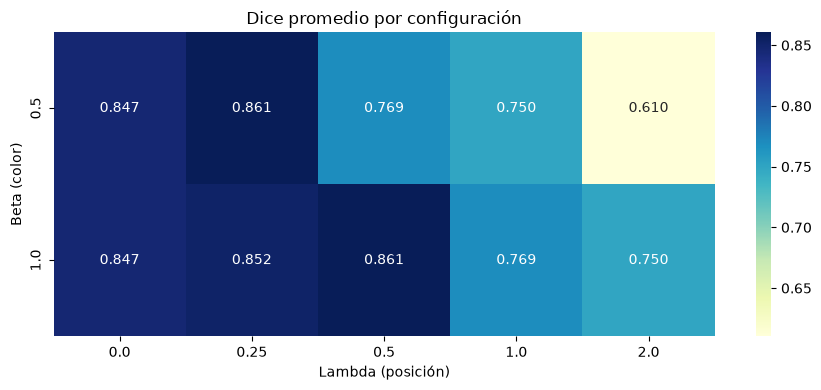

In [19]:

# Preparar tabla para visualizar Dice promedio
tabla_dice = df_resultados.pivot_table(
    index="Beta",
    columns="Lambda",
    values="Dice",
    aggfunc="mean"
)

plt.figure(figsize=(9, 4))

import seaborn as sns

sns.heatmap(
    tabla_dice,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)

plt.title("Dice promedio por configuración")
plt.xlabel("Lambda (posición)")
plt.ylabel("Beta (color)")
plt.tight_layout()
plt.show()


La mejor configuración fue beta=0.5 y lambda= 0.25

Podemos concluir trea cosas: El color es fundamental, la información espacial ayuda relativo a no usarlo, la mejor configuración es bastante estable

In [20]:

# Configuración candidata según el Dice promedio de ajuste
mejor_beta = 1.0
mejor_lambda = 0.5

print("Beta:", mejor_beta)
print("Lambda:", mejor_lambda)

# Consultar los resultados de esta configuración
mejor_configuracion = df_resultados[
    (df_resultados["Beta"] == mejor_beta) &
    (df_resultados["Lambda"] == mejor_lambda)
]

display(mejor_configuracion)


Beta: 1.0
Lambda: 0.5


,Imagen,Beta,Lambda,K,Silueta,Dice,V-measure
7,ISIC_0000085,1.0,0.5,2,0.522892,0.902548,0.760299
17,ISIC_0000086,1.0,0.5,2,0.519601,0.931682,0.793246
27,ISIC_0000089,1.0,0.5,2,0.623441,0.940426,0.839631
37,ISIC_0000094,1.0,0.5,5,0.407242,0.882998,0.206685
47,ISIC_0000108,1.0,0.5,2,0.559317,0.910233,0.764625
57,ISIC_0000112,1.0,0.5,5,0.429323,0.770086,0.226000
67,ISIC_0000114,1.0,0.5,5,0.365656,0.743377,0.108289
77,ISIC_0000116,1.0,0.5,5,0.461033,0.745572,0.285789
87,ISIC_0000122,1.0,0.5,5,0.486798,0.888114,0.378442
97,ISIC_0000133,1.0,0.5,2,0.452673,0.739818,0.425755


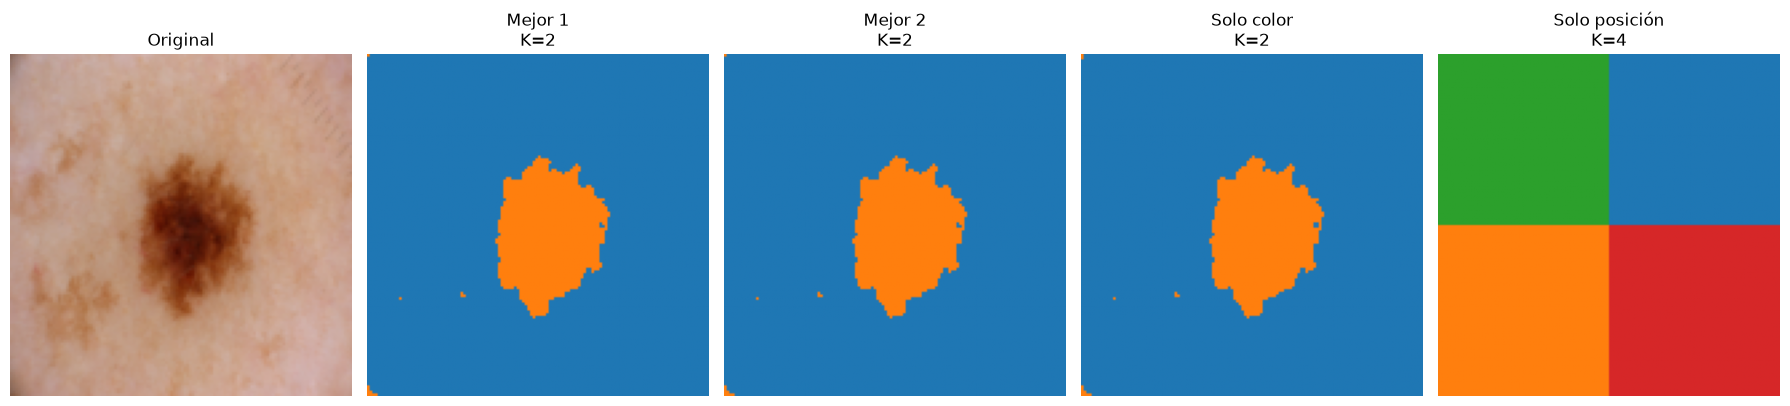

In [21]:

# Imagen de ajuste para comparar configuraciones
imagen, mascara = cargar_imagen("ISIC_0000085")

comparaciones = [
    ("Mejor 1", 0.5, 0.25),
    ("Mejor 2", 1.0, 0.5),
    ("Solo color", 1.0, 0.0),
    ("Solo posición", 0.0, 1.0)
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(imagen)
axes[0].set_title("Original")
axes[0].axis("off")

for i, (nombre, beta, lambda_) in enumerate(comparaciones, 1):
    pipeline.set_params(
        representacion__beta=beta,
        representacion__lambda_=lambda_
    )

    X = pipeline.fit_transform(imagen)
    k, tabla = seleccionar_k(X)

    modelo = KMeans(n_clusters=k, random_state=42, n_init=5)
    grupos = modelo.fit_predict(X).reshape(imagen.shape[:2])

    axes[i].imshow(grupos, cmap="tab10", vmin=0, vmax=9)
    axes[i].set_title(f"{nombre}\nK={k}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


### Consulta a la IAG

Estoy diseñando un método de segmentación no supervisada para imágenes dermatoscópicas con lesiones generalmente más oscuras que la piel circundante. Represento los píxeles como [βR, βG, βB, λx, λy] con características normalizadas. ¿Qué valores de β, λ y K recomiendas explorar con K-means y cómo identificarías automáticamente los grupos de la lesión? Justifica tu recomendación y sus posibles limitaciones.


## Punto 5
Evaluación final con las cinco imagenes de prueba. Vamos a calcular las métricas que se piden

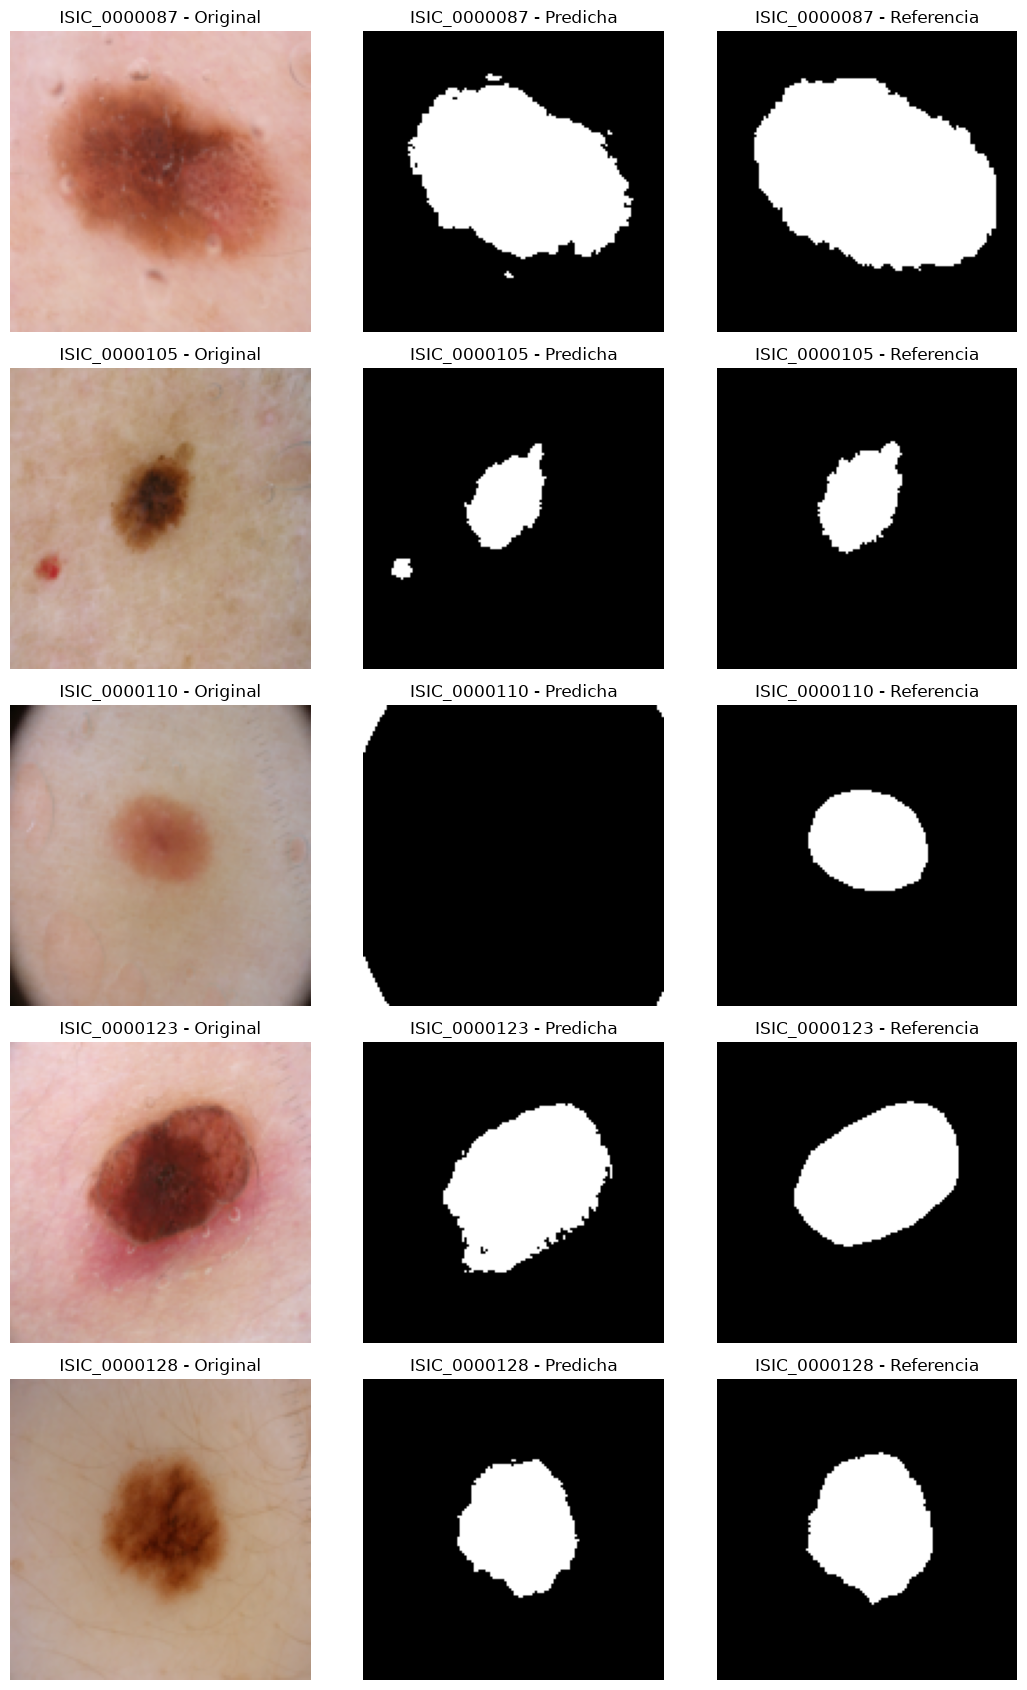

,Imagen,K,Silueta,Dice,V-measure,Precision,Recall
0,ISIC_0000087,2,0.4926,0.8819,0.6410,0.9968,0.7908
1,ISIC_0000105,5,0.4159,0.8888,0.2132,0.9423,0.8410
2,ISIC_0000110,6,0.4037,0.0000,0.1801,0.0000,0.0000
3,ISIC_0000123,2,0.5434,0.8999,0.6967,0.8509,0.9549
4,ISIC_0000128,2,0.5555,0.9329,0.8178,1.0000,0.8742


In [22]:

from sklearn.metrics import precision_score, recall_score

def evaluar_prueba(id_imagen):
    imagen, mascara_real = cargar_imagen(id_imagen, "prueba")

    pipeline.set_params(
        representacion__beta=1.0,
        representacion__lambda_=0.5
    )

    X = pipeline.fit_transform(imagen)

    k, tabla_k = seleccionar_k(X)

    modelo = KMeans(n_clusters=k, random_state=42, n_init=5)
    etiquetas = modelo.fit_predict(X)
    grupos = etiquetas.reshape(imagen.shape[:2])

    mascara_predicha, grupo_lesion = crear_mascara(imagen, grupos)

    real = mascara_real.ravel()
    predicha = mascara_predicha.ravel()

    metricas = {
        "Imagen": id_imagen,
        "K": k,
        "Silueta": tabla_k["Silueta"].max(),
        "Dice": f1_score(real, predicha, zero_division=0),
        "V-measure": v_measure_score(real, etiquetas),
        "Precision": precision_score(real, predicha, zero_division=0),
        "Recall": recall_score(real, predicha, zero_division=0)
    }

    return metricas, imagen, mascara_real, mascara_predicha


ids_prueba = sorted([
    archivo.stem
    for archivo in (RUTA_DATOS / "prueba" / "imagenes").glob("*.jpg")
])

resultados_prueba = []

fig, axes = plt.subplots(5, 3, figsize=(11, 17))

for i, id_imagen in enumerate(ids_prueba):
    metricas, imagen, real, predicha = evaluar_prueba(id_imagen)
    resultados_prueba.append(metricas)

    for j, (contenido, titulo) in enumerate([
        (imagen, "Original"),
        (predicha, "Predicha"),
        (real, "Referencia")
    ]):
        axes[i, j].imshow(
            contenido,
            cmap="gray" if j > 0 else None
        )
        axes[i, j].set_title(f"{id_imagen} - {titulo}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

df_prueba = pd.DataFrame(resultados_prueba)
display(df_prueba.round(4))


In [23]:

dice_ajuste = mejor_configuracion["Dice"].mean()
dice_prueba = df_prueba["Dice"].mean()

comparacion = pd.DataFrame({
    "Conjunto": ["Ajuste", "Prueba"],
    "Dice promedio": [dice_ajuste, dice_prueba]
})

display(comparacion.round(4))

print("Diferencia de Dice:", round(dice_ajuste - dice_prueba, 4))


,Conjunto,Dice promedio
0,Ajuste,0.8606
1,Prueba,0.7207


Diferencia de Dice: 0.1399


## Análisis de resultados

¿Qué efecto tuvo incluir la posición de los píxeles? Expliquen en qué imágenes mejoró o perjudicó la segmentación y por qué.

Tuvo un efecto positivo. Considerar la posición es importatnte porque las lesiones se encuentran en un punto focalizado, es decir que toda la lesión se encuentra en un área y la piel está en los alrededores y no aparecerá más de este. Esto es útil porque el modelo puede saber que, así crea que el píxel hace parte de la lesión por su color, si se encuentra muy alejado de la zona de la lesión, lo más probable es que no haga parte de ese grupo. 

¿Qué relación encontraron entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?



¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?

Identifiquen dos limitaciones de su modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.

En el contexto de DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse antes de utilizar el método con nuevas poblaciones o condiciones de adquisición?